# T20 phase 1: full-corpus galaxy-ID pass, design and runtime estimate

Companion notebook to `README.md`. Regenerates every figure from `data/` (produced by `tools/audit/galaxy_phase1_data.py`; no drive needed).

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
REPORT = REPO / "reports" / "2026-10-21_t20-galaxy-pass-phase1"
FIG, DATA = REPORT / "figures", REPORT / "data"
FIG.mkdir(exist_ok=True)
bench = pd.read_csv(DATA / "bench_meta.csv")
summ = json.loads((DATA / "groups_summary.json").read_text())
tab = pd.read_csv(DATA / "galaxy_table.csv")
sib = pd.read_csv(DATA / "galaxy_siblings.csv")
asg = pd.read_csv(DATA / "galaxy_assign.csv.gz")
runs = pd.read_csv(DATA / "bench_runs.csv")

## 1. Runtime benchmark

`bench_runs.csv` holds the wall time of each benchmark invocation (k workers, k or 2k distinct cold bundles); `bench_meta.csv` the per-bundle timings each worker recorded.

,label,n_workers,n_bundles,bundles,wall_s,note,s_per_bundle,bundles_per_min,full_corpus_min
0,1w x1,1,1,090,18,cold drive read,18.000000,3.333333,54.00
1,2w x2,2,2,001 180,24,001 had been read ~5 min earlier (possibly pag...,12.000000,5.000000,36.00
2,3w x3,3,3,045 135 165,24,cold,8.000000,7.500000,24.00
3,4w x4,4,4,015 060 105 150,39,cold; 4 workers + 4 gzip processes on 4 physic...,9.750000,6.153846,29.25
4,3w x6,3,6,030 075 120 010 100 170,51,cold; two rounds (sustained),8.500000,7.058824,25.50
5,3w x15,3,15,002-018 (not yet done),142,cold; concurrent with my own test/dev processe...,9.466667,6.338028,28.40


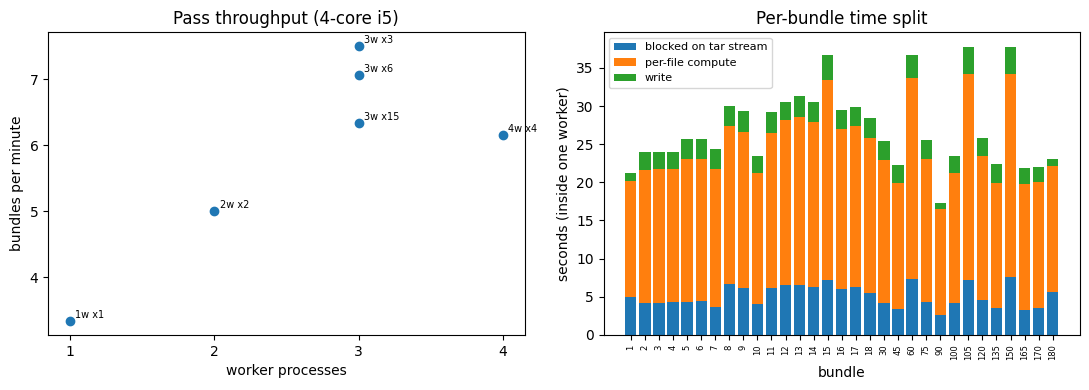

In [2]:
runs["s_per_bundle"] = runs.wall_s / runs.n_bundles
runs["bundles_per_min"] = 60 / runs.s_per_bundle
runs["full_corpus_min"] = 180 * runs.s_per_bundle / 60
display(runs)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(runs.n_workers, runs.bundles_per_min, "o")
for _, r in runs.iterrows():
    ax[0].annotate(r.label, (r.n_workers, r.bundles_per_min), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set(xlabel="worker processes", ylabel="bundles per minute", title="Pass throughput (4-core i5)")
ax[0].set_xticks([1, 2, 3, 4])
b = bench.sort_values("bundle")
ax[1].bar(b.bundle.astype(str), b.tar_stream_s, label="blocked on tar stream")
ax[1].bar(b.bundle.astype(str), b.compute_s, bottom=b.tar_stream_s, label="per-file compute")
ax[1].bar(b.bundle.astype(str), b.write_s, bottom=b.tar_stream_s + b.compute_s, label="write")
ax[1].set(xlabel="bundle", ylabel="seconds (inside one worker)", title="Per-bundle time split")
ax[1].tick_params(axis="x", rotation=90, labelsize=6); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "benchmark.png", dpi=120)

## 2. Fingerprint correlations: members vs other galaxies

For every file in the three benchmark bundles, the correlation with its own galaxy template (`corr_best`) and with the best *other* template (`corr_second`).

files with corr_best < 0.9: 0.009461381485375054  < 0.99: 0.049223919361820544
files with corr_second > 0.9: 284


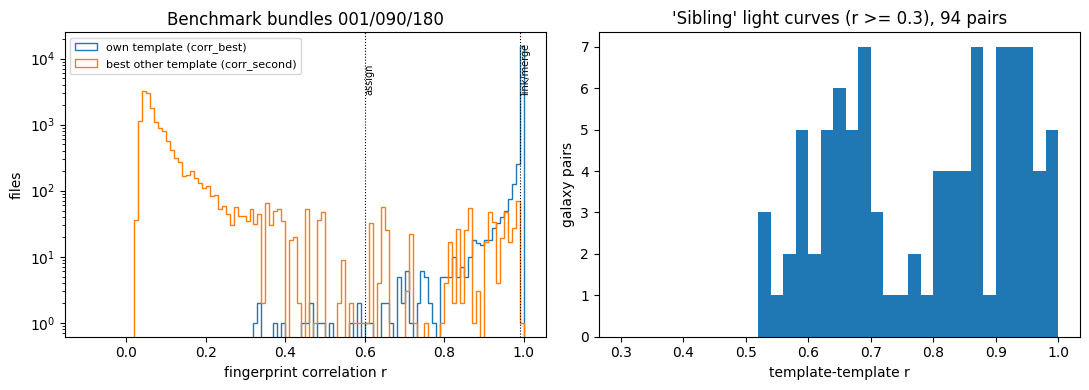

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(-0.1, 1.0, 111)
ax[0].hist(asg.corr_best, bins, histtype="step", label="own template (corr_best)")
ax[0].hist(asg.corr_second, bins, histtype="step", label="best other template (corr_second)")
for x, l in ((0.6, "assign"), (0.99, "link/merge")):
    ax[0].axvline(x, color="k", ls=":", lw=0.8); ax[0].text(x, 3e3, l, rotation=90, fontsize=7)
ax[0].set(yscale="log", xlabel="fingerprint correlation r", ylabel="files", title="Benchmark bundles 001/090/180")
ax[0].legend(fontsize=8)
ax[1].hist(sib["corr"], np.linspace(0.3, 1, 36))
ax[1].set(xlabel="template-template r", ylabel="galaxy pairs", title=f"'Sibling' light curves (r >= 0.3), {len(sib)} pairs")
fig.tight_layout(); fig.savefig(FIG / "correlations.png", dpi=120)
print("files with corr_best < 0.9:", (asg.corr_best < 0.9).mean(), " < 0.99:", (asg.corr_best < 0.99).mean())
print("files with corr_second > 0.9:", (asg.corr_second > 0.9).sum())

## 3. Group sizes

Left: files per galaxy within one bundle (each bundle covers a 1-day period range). Right: total members per galaxy over all bundles processed so far.

pool
lt800k only    999
ge800k only    718
both             1
Name: count, dtype: int64

,galaxy_id,n_files,n_lt800k,n_ge800k,n_bundles,n_corrupt,corr_best_min,corr_best_median,p2p_ppm_median,slow_rms_ppm_median,period_min,period_max,sibling_group,max_sibling_corr,pool
2,2,211,164,47,31,0,0.990982,0.999714,798.395346,659.283908,0.2168,179.6171,2,NaN,both


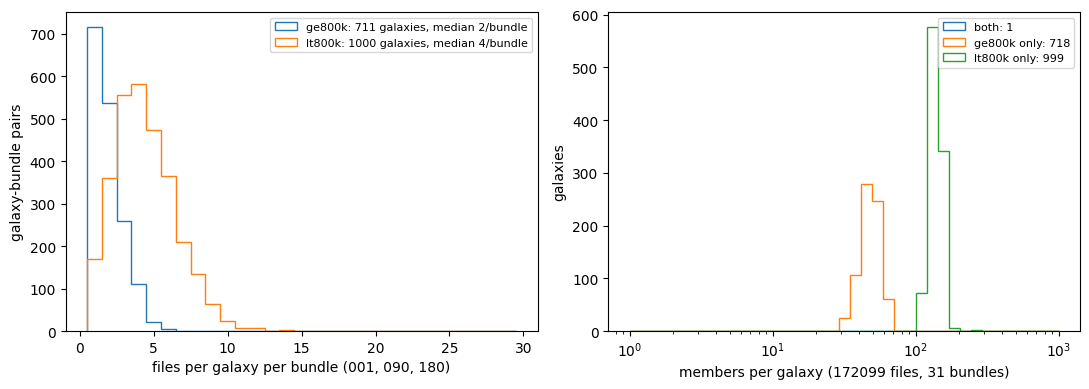

In [4]:
pb = pd.read_csv(DATA / "per_bundle_group_sizes.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for pool, g in pb.groupby("pool"):
    ax[0].hist(g.n_files, np.arange(0.5, 30.5), histtype="step", label=f"{pool}: {g.galaxy_id.nunique()} galaxies, median {g.n_files.median():.0f}/bundle")
ax[0].set(xlabel="files per galaxy per bundle (001, 090, 180)", ylabel="galaxy-bundle pairs"); ax[0].legend(fontsize=8)
tab["pool"] = np.where(tab.n_ge800k == 0, "lt800k only", np.where(tab.n_lt800k == 0, "ge800k only", "both"))
for pool, g in tab.groupby("pool"):
    ax[1].hist(g.n_files, np.logspace(0, 3, 40), histtype="step", label=f"{pool}: {len(g)}")
ax[1].set(xscale="log", xlabel=f"members per galaxy ({summ['n_files']} files, {len(summ['bundles'])} bundles)", ylabel="galaxies")
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "group_sizes.png", dpi=120)
display(tab.pool.value_counts())
display(tab[tab.pool == "both"])

## 4. Spot check: members of one galaxy share the noise, not the signal

Three galaxies from bundle 090 (4 members each), full year (left, offset for clarity) and a 3-day zoom (right). The last two rows are a sibling pair (distinct light curves with high fingerprint r).

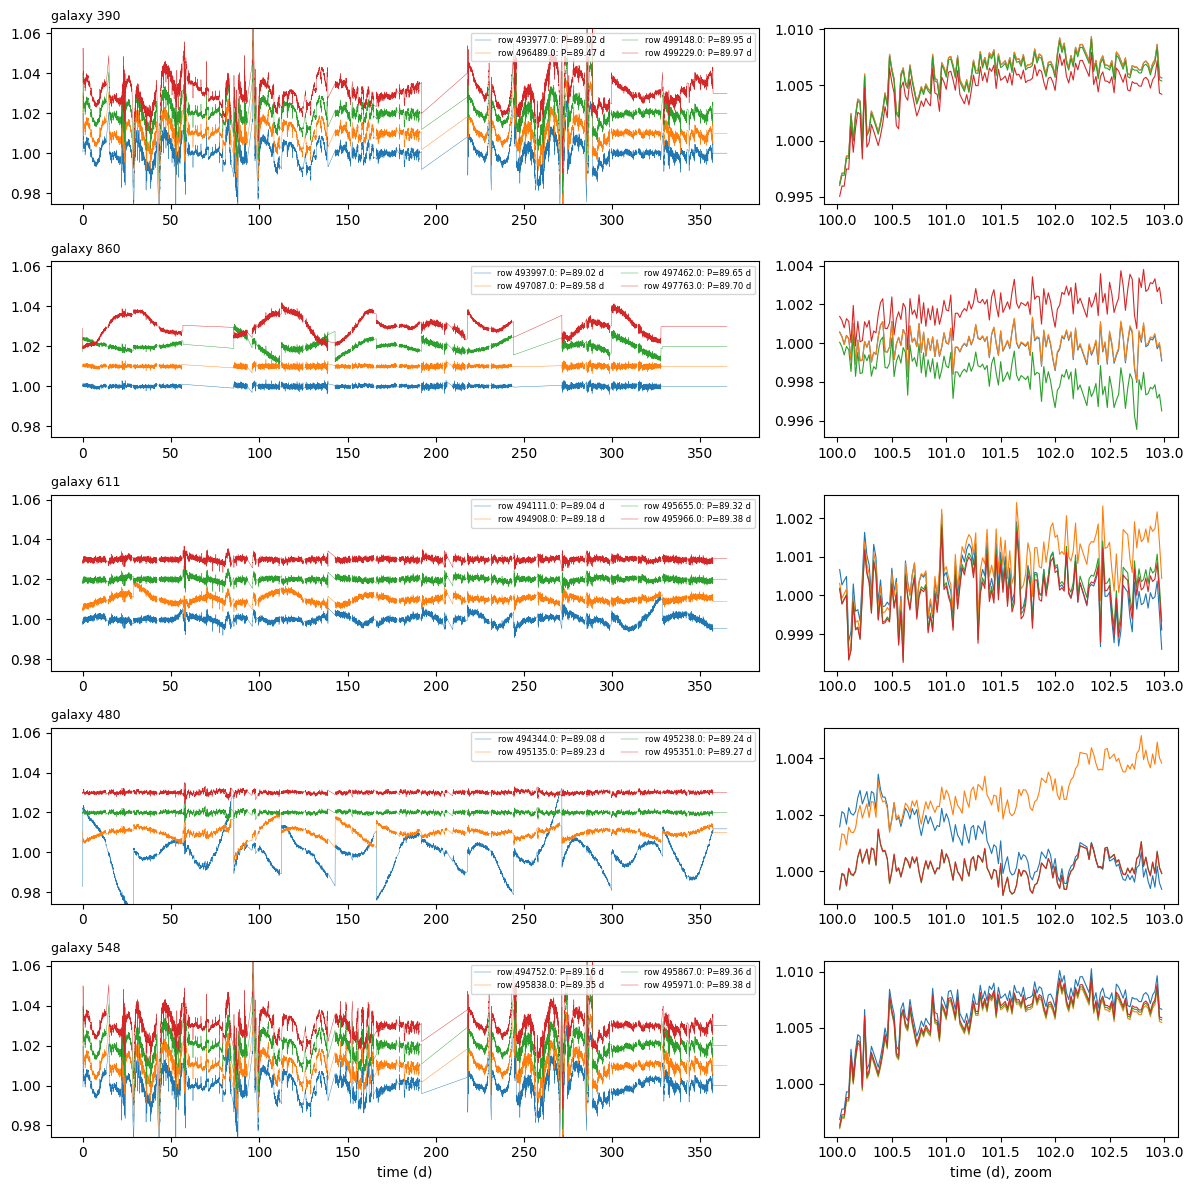

In [5]:
z = np.load(DATA / "spotcheck_flux.npz"); mem = pd.read_csv(DATA / "spotcheck_members.csv")
t, rows, F = z["time"], z["rows"], z["flux"]
gals = list(dict.fromkeys(mem.galaxy_id))
fig, ax = plt.subplots(len(gals), 2, figsize=(12, 2.4 * len(gals)), gridspec_kw=dict(width_ratios=[2, 1]))
zoom = (t > 100) & (t < 103)
for i, g in enumerate(gals):
    m = mem[mem.galaxy_id == g]
    for j, (_, r) in enumerate(m.iterrows()):
        f = F[list(rows).index(r.row)]
        ax[i, 0].plot(t, f + 0.01 * j, lw=0.3, label=f"row {r.row}: P={r.period:.2f} d")
        ax[i, 1].plot(t[zoom], f[zoom], lw=0.8)
    ax[i, 0].set_ylim(np.nanpercentile(F, 0.5) - 0.005, np.nanpercentile(F, 99.5) + 0.04)
    ax[i, 0].set_title(f"galaxy {g}", fontsize=9, loc="left"); ax[i, 0].legend(fontsize=6, loc="upper right", ncol=2)
ax[-1, 0].set_xlabel("time (d)"); ax[-1, 1].set_xlabel("time (d), zoom")
fig.tight_layout(); fig.savefig(FIG / "spotcheck.png", dpi=120)

## 5. T1 cross-check and corrupt galaxies

In [6]:
print(json.loads((DATA / "t1_validation.json").read_text()))
mm = pd.read_csv(DATA / "t1_validation_mismatches.csv"); display(mm.head(20))
print("galaxies with >=1 corrupt member:", (tab.n_corrupt > 0).sum(), "of", len(tab),
      "; of those, all members corrupt:", ((tab.n_corrupt == tab.n_files) & (tab.n_corrupt > 0)).sum())
mixed = tab[(tab.n_corrupt > 0) & (tab.n_corrupt < tab.n_files)]
display(mixed.head(10))

{'n_rows_overlap': 1031, 'n_t1_rows': 1050, 't1_same_pairs': 376, 'our_same_pairs': 371, 'both': 371, 't1_only': 5, 'ours_only': 0}


,row_a,row_b,t1_same,ours_same
0,23200,90000,True,False
1,23600,90000,True,False
2,47200,90000,True,False
3,56500,57100,True,False
4,88700,92500,True,False


galaxies with >=1 corrupt member: 222 of 1718 ; of those, all members corrupt: 204


,galaxy_id,n_files,n_lt800k,n_ge800k,n_bundles,n_corrupt,corr_best_min,corr_best_median,p2p_ppm_median,slow_rms_ppm_median,period_min,period_max,sibling_group,max_sibling_corr,pool
157,157,151,151,0,31,2,0.949846,0.999528,563.507023,967.045957,0.3879,179.6844,155,NaN,lt800k only
158,158,151,151,0,30,1,0.983868,0.999883,1291.323396,733.361103,1.8148,179.9223,156,NaN,lt800k only
271,271,145,145,0,31,1,0.990699,0.999932,1351.342080,2045.277670,0.1827,179.6768,265,NaN,lt800k only
311,311,144,144,0,31,1,0.997401,0.999949,1816.244747,840.712577,0.2967,179.8778,305,NaN,lt800k only
320,320,144,144,0,31,1,0.990124,0.999943,2148.925096,1264.421456,0.5802,179.6438,314,NaN,lt800k only
330,330,143,143,0,31,1,0.791473,0.999775,707.570611,589.423528,0.1272,179.9163,324,0.950766,lt800k only
390,390,141,141,0,31,1,0.925782,0.999946,847.291359,3552.826826,0.1730,179.8962,383,0.989037,lt800k only
399,399,141,141,0,31,1,0.968409,0.999935,1357.528285,965.459942,0.1269,179.4703,392,NaN,lt800k only
416,416,140,140,0,31,1,0.980667,0.999810,789.381608,841.348805,0.1495,179.9340,409,NaN,lt800k only
434,434,140,140,0,31,1,0.955209,0.999612,441.969968,707.947408,0.3613,179.9307,427,NaN,lt800k only
